**Sales Analysis Dashboard**

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import dash
from dash import dcc, html
from dash.dependencies import Input, Output
import plotly.express as px

# Load dataset
df = pd.read_csv("/content/amazon.csv")


1. Data Cleaning

In [19]:



# Remove duplicates
df.drop_duplicates(inplace=True)

# Handle missing values for numeric columns
df.fillna({
    'discounted_price': 0,
    'actual_price': 0,
    'discount_percentage': 0,
    'rating': 0,
    'rating_count': 0
}, inplace=True)

# Ensure numeric columns are proper type
numeric_cols = ['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

2. Data Aggregation

In [20]:

# Total sales per product category
df['total_sales'] = df['discounted_price'] * df['rating_count']  # assuming total sales = price * number of buyers
category_sales = df.groupby('category')['total_sales'].sum().sort_values(ascending=False)

# Average sales per category
avg_category_sales = df.groupby('category')['total_sales'].mean().sort_values(ascending=False)

# Total number of reviews per product
reviews_per_product = df.groupby('product_name')['review_id'].count().sort_values(ascending=False)

# Top-rated products
top_rated_products = df.groupby('product_name')['rating'].mean().sort_values(ascending=False).head(10)

3. Data Visualizations

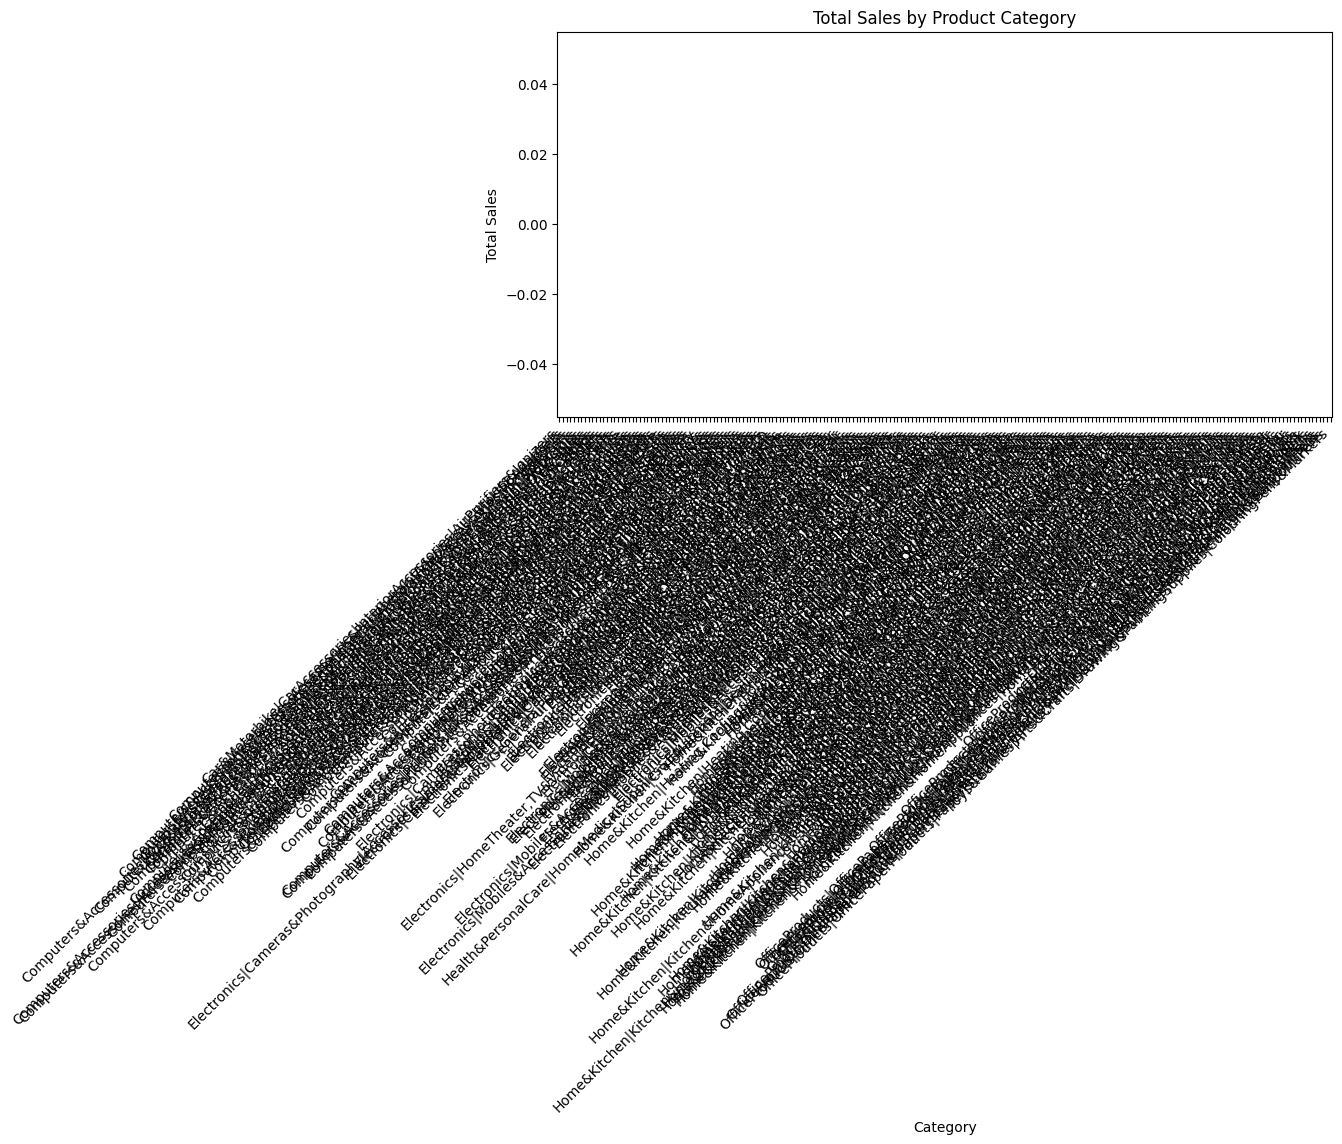

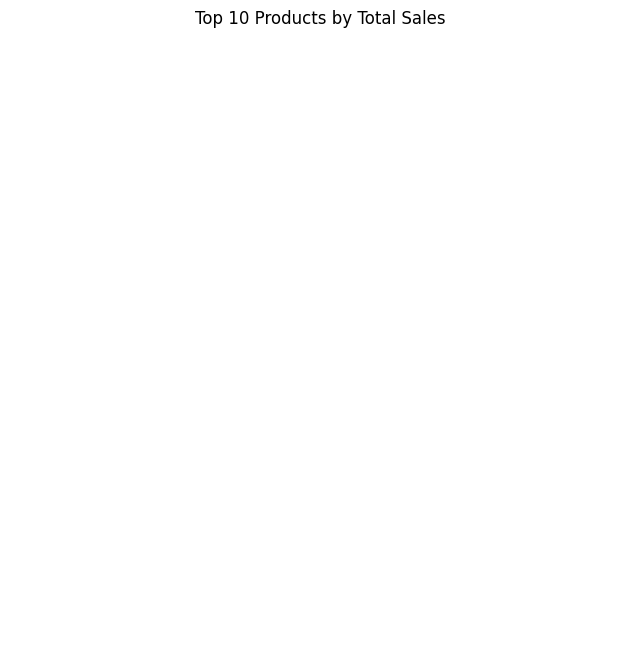

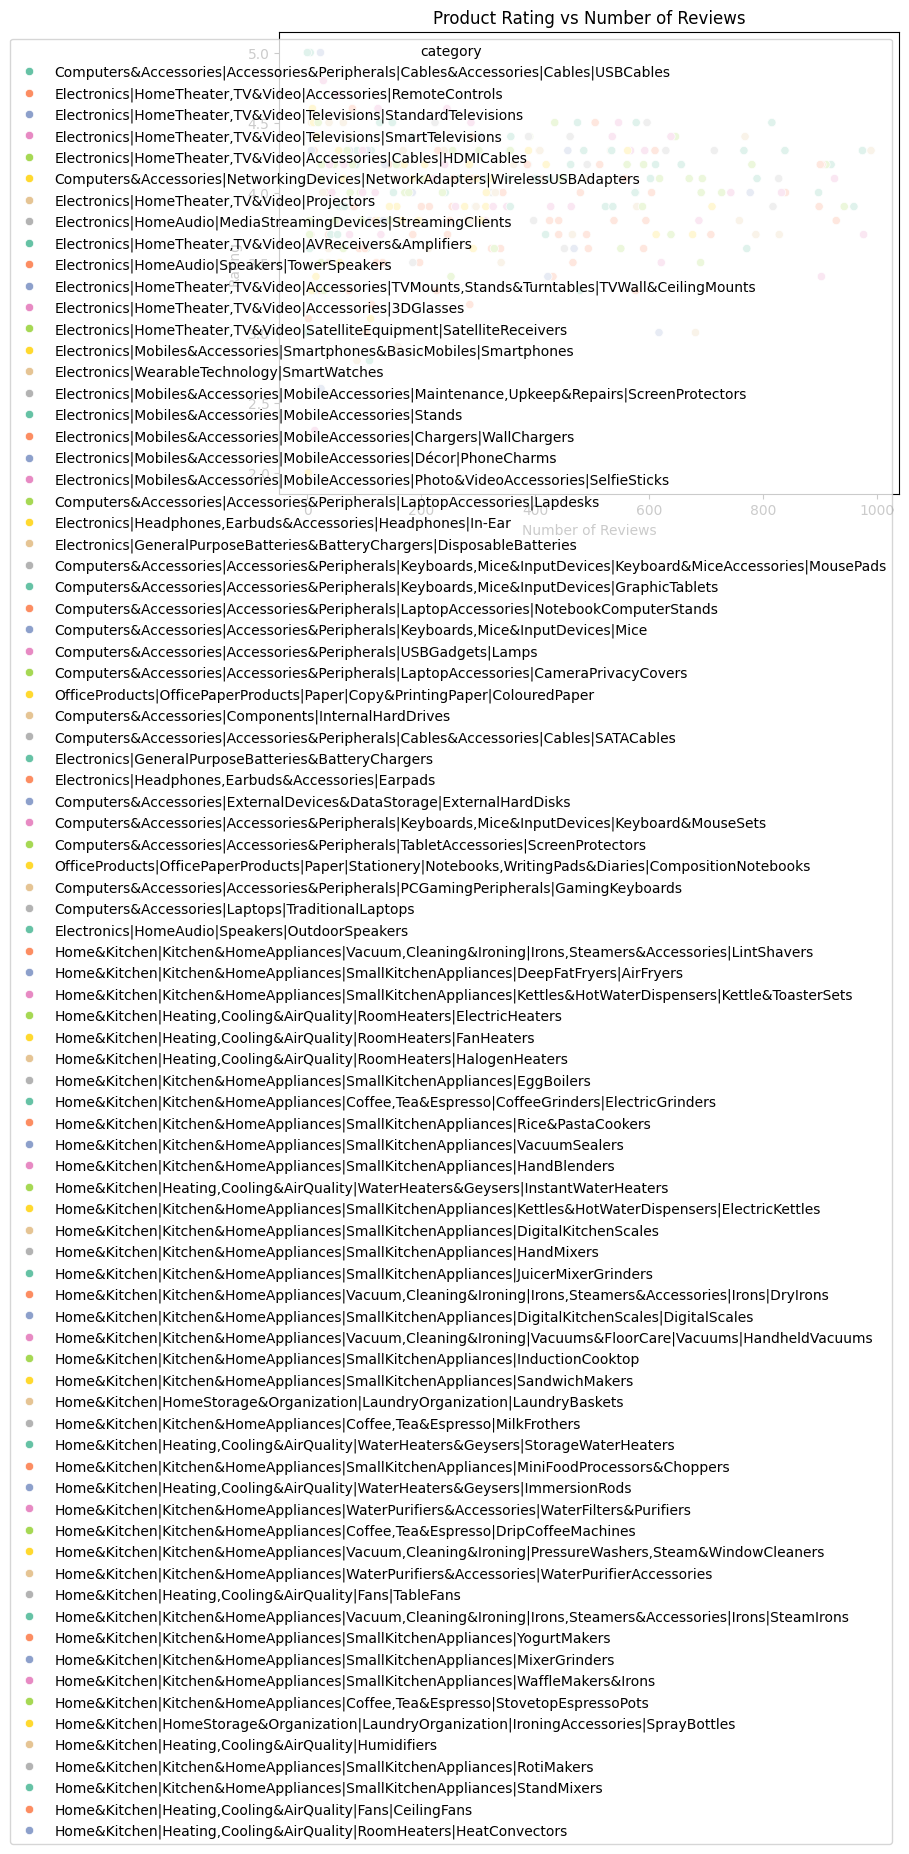

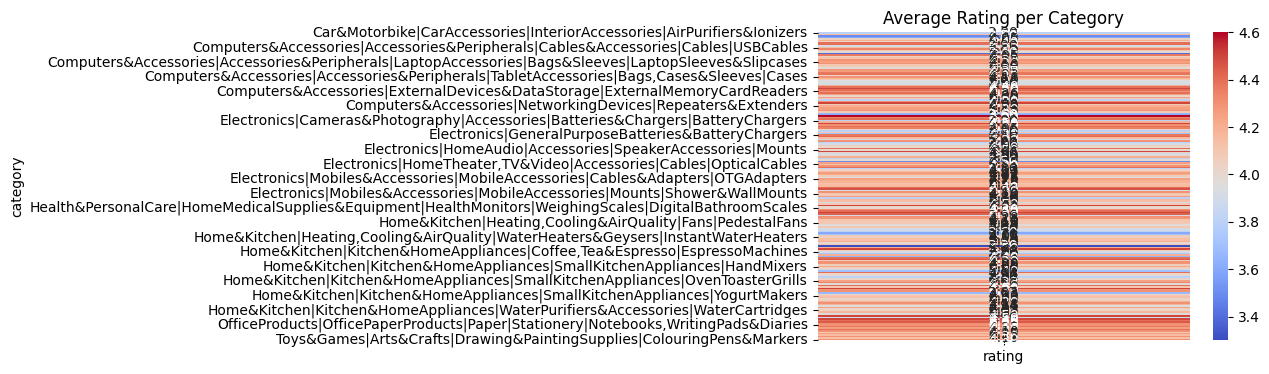

In [21]:


# Bar chart - Sales distribution by category
plt.figure(figsize=(10,5))
category_sales.plot(kind='bar', color='skyblue')
plt.title('Total Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.show()

# Pie chart - Top 10 Products by total sales
top_products = df.groupby('product_name')['total_sales'].sum().sort_values(ascending=False).head(10)

# Remove NaN or zero sales
top_products = top_products[top_products > 0]

plt.figure(figsize=(8,8))
plt.pie(top_products, labels=top_products.index, autopct='%1.1f%%', startangle=90)
plt.title('Top 10 Products by Total Sales')
plt.axis('equal')
plt.show()

# Scatter plot - Rating vs Number of Reviews
# Remove rows with NaN in rating or rating_count
scatter_df = df[['rating', 'rating_count', 'category']].dropna()

plt.figure(figsize=(8,6))
sns.scatterplot(x='rating_count', y='rating', hue='category', data=scatter_df, palette='Set2')
plt.title('Product Rating vs Number of Reviews')
plt.xlabel('Number of Reviews')
plt.ylabel('Rating')
plt.show()

# Heatmap - Average rating per category
avg_rating_category = df.pivot_table(values='rating', index='category', aggfunc='mean')

plt.figure(figsize=(6,4))
sns.heatmap(avg_rating_category, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Average Rating per Category')
plt.show()


4. Dashboard

In [22]:

# Ensure numeric columns are correct
numeric_cols = ['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
df['total_sales'] = df['discounted_price'] * df['rating_count']

# If you have order_date column, convert to datetime
if 'order_date' in df.columns:
    df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
else:
    # create a dummy date column for demo
    import numpy as np
    df['order_date'] = pd.date_range(start='2024-01-01', periods=len(df), freq='D')

# ------------------------------
# Initialize Dash app
# ------------------------------
app = dash.Dash(__name__)
app.title = "Sales Dashboard"

# ------------------------------
# Layout
# ------------------------------
app.layout = html.Div([
    html.H1("eCommerce Sales Dashboard", style={'textAlign':'center'}),

    html.Div([
        html.Label("Select Product Category:"),
        dcc.Dropdown(
            id='category-filter',
            options=[{'label': cat, 'value': cat} for cat in df['category'].unique()],
            multi=True,
            value=df['category'].unique().tolist()
        ),
    ], style={'width':'30%', 'display':'inline-block', 'margin-right':'20px'}),

    html.Div([
        html.Label("Select Date Range:"),
        dcc.DatePickerRange(
            id='date-filter',
            start_date=df['order_date'].min(),
            end_date=df['order_date'].max()
        ),
    ], style={'display':'inline-block'}),

    html.Div([
        dcc.Graph(id='sales-trend-line'),
        dcc.Graph(id='sales-by-category-bar'),
        dcc.Graph(id='top-products-pie'),
        dcc.Graph(id='rating-vs-reviews-scatter')
    ])
])

# ------------------------------
# Callbacks for Interactivity
# ------------------------------
@app.callback(
    [Output('sales-trend-line', 'figure'),
     Output('sales-by-category-bar', 'figure'),
     Output('top-products-pie', 'figure'),
     Output('rating-vs-reviews-scatter', 'figure')],
    [Input('category-filter', 'value'),
     Input('date-filter', 'start_date'),
     Input('date-filter', 'end_date')]
)
def update_dashboard(selected_categories, start_date, end_date):
    # Filter data
    filtered_df = df[df['category'].isin(selected_categories)]
    filtered_df = filtered_df[(filtered_df['order_date'] >= start_date) & (filtered_df['order_date'] <= end_date)]

    # 1Sales Trend Line
    sales_trend = filtered_df.groupby(filtered_df['order_date'].dt.to_period('M'))['total_sales'].sum().reset_index()
    sales_trend['order_date'] = sales_trend['order_date'].dt.to_timestamp()
    fig_line = px.line(sales_trend, x='order_date', y='total_sales', title='Sales Trend Over Time')

    #  Sales by Category Bar
    sales_by_cat = filtered_df.groupby('category')['total_sales'].sum().reset_index()
    fig_bar = px.bar(sales_by_cat, x='category', y='total_sales', title='Total Sales by Category')

    # Top Products Pie
    top_products = filtered_df.groupby('product_name')['total_sales'].sum().sort_values(ascending=False).head(10).reset_index()
    fig_pie = px.pie(top_products, names='product_name', values='total_sales', title='Top 10 Products by Sales')

    # Rating vs Reviews Scatter
    scatter_df = filtered_df[['rating', 'rating_count', 'category']].dropna()
    fig_scatter = px.scatter(scatter_df, x='rating_count', y='rating', color='category',
                             title='Rating vs Number of Reviews', hover_data=['category'])

    return fig_line, fig_bar, fig_pie, fig_scatter

# ------------------------------
# Run the app
# ------------------------------
if __name__ == '__main__':
    app.run(debug=True)

<IPython.core.display.Javascript object>

5. Insights Preparation

In [16]:


# ------------------------------

# Top 5 categories by total sales
top_categories = category_sales.head(5)
print("\nTop 5 Categories by Total Sales:")
print(top_categories)

# Top 5 products by average rating
top_products_rating = top_rated_products.head(5)
print("\nTop 5 Products by Average Rating:")
print(top_products_rating)

# Top 5 reviewers by number of reviews
top_reviewers = df.groupby('user_name')['review_id'].count().sort_values(ascending=False).head(5)
print("\nTop 5 Reviewers:")
print(top_reviewers)



Top 5 Categories by Total Sales:
category
Car&Motorbike|CarAccessories|InteriorAccessories|AirPurifiers&Ionizers                0.0
Computers&Accessories|Accessories&Peripherals|Adapters|USBtoUSBAdapters               0.0
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCHeadsets       0.0
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCMicrophones    0.0
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCSpeakers       0.0
Name: total_sales, dtype: float64

Top 5 Products by Average Rating:
product_name
Syncwire LTG to USB Cable for Fast Charging Compatible with Phone 5/ 5C/ 5S/ 6/ 6S/ 7/8/ X/XR/XS Max/ 11/12/ 13 Series and Pad Air/Mini, Pod & Other Devices (1.1 Meter, White)                                                                                                 5.0
REDTECH USB-C to Lightning Cable 3.3FT, [Apple MFi Certified] Lightning to Type C Fast Charging Cord Compatible with iPhone 14/13/13 pro/Max/12/11/X/